# Spatial CNV inference on Xenium

Imaging-based spatial transcriptomics (Xenium, CosMx, MERSCOPE) measures a few hundred to a few thousand genes in tens
to hundreds of thousands of cells, with a few hundred counts per cell. inferCNV-style profiles of single cells are noisy
at that depth, but the tissue coordinates add information, because neighboring tumor cells usually share their copy
number state. The tutorial uses

- {func}`infercnvpy.tl.detectability` to see which chromosome arms the panel and depth can resolve, and to plan a panel,
- {func}`infercnvpy.tl.smooth_cnv` to average each cell's CNV profile with its spatial neighbors,
- {func}`infercnvpy.tl.spatial_regions` to make per-cell labels (here tumor and normal calls) spatially coherent, so
  that a cell takes the label of its neighborhood when most of its neighbors disagree with it (more than 75% at the
  default `beta`),
- {func}`infercnvpy.pl.spatial_cnv` to plot the mean CNV of a chromosome or arm on the tissue,
- {func}`infercnvpy.tl.copy_number` to call aneuploid cells and clones from the raw counts.

The spatial tools read a spatial neighbor graph from `adata.obsp`, here from {func}`squidpy.gr.spatial_neighbors_knn`,
and any cells x cells graph works. To run the tutorial, install squidpy, gtfparse and the lazy readers of anndata with
the optional extras, and s3fs to read the data from S3: `pip install "infercnvpy[spatial,gtf,dask]" s3fs`.

The ideas are not new. InSituCNV {cite}`Jensen2025` smooths the normalized expression over a kNN graph of expression
similarity and then runs infercnvpy, SlideCNA {cite}`Zhang2025` pools spatial neighbors on Slide-seq, and STARCH
{cite}`Elyanow2021` and CalicoST {cite}`Ma2024` make neighboring cells prefer the same clone label. In a benchmark of
CNV inference on spatial data, {cite:t}`Han2026` found that aggregating cells on imaging platforms improved CNV recovery
compared to native single-cell resolution.

We use a Xenium Prime 5K section of a squamous cell lung carcinoma from {cite:t}`Bilous2026`, distributed under GEO
terms through the scverse spatial data catalogue. Squamous lung cancers typically lose 3p and gain distal 3q (3q26 to
the end of the arm, with SOX2, TP63 and PIK3CA), and they often gain 5p and lose 8p, 9p and 13q. Squamous lineage genes
sit in the same region of 3q, which matters below.

In [1]:
import importlib.metadata
import os
import time

import anndata as ad
import matplotlib.pyplot as plt
import numba
import numpy as np
import pandas as pd
import pooch
import scanpy as sc
import squidpy as sq
import zarr
from matplotlib_inline.backend_inline import set_matplotlib_formats
from scipy.spatial import KDTree

import infercnvpy as cnv

# Spatial maps: one map per row, about 850 px wide at dpi=100, which fills the width of the documentation page.
# The other plots set their own figsize.
sc.set_figure_params(dpi=100, frameon=False, figsize=(12.5, 9.5))
set_matplotlib_formats("jpeg", pil_kwargs={"quality": 90})


def legend_below(axes):
    """Show the maps with the legend of each categorical map below it instead of to its right.

    Only the layout changes: the map gets the full width. Without it, call `cnv.pl.spatial_cnv` directly.
    """
    for ax in np.atleast_1d(axes):
        if (legend := ax.get_legend()) is not None:
            labels = [t.get_text() for t in legend.get_texts()]
            ax.legend(
                legend.legend_handles,
                labels,
                loc="upper center",
                bbox_to_anchor=(0.5, 0),
                ncols=min(len(labels), 5),
                frameon=False,
                markerscale=1.5,
            )
    plt.show()

## Load the data

The dataset is a SpatialData object on S3. We only need its table, which we open lazily with
{func}`anndata.experimental.read_lazy` and then load the counts, the cell metadata and the cell centroids into memory.
Images, transcripts and segmentation shapes are never downloaded.

In [2]:
group = zarr.open_group(
    "s3://scverse-spatial-eu-central-1/.lamindb/cOjo8Fe6mVpB4Mu0.zarr/tables/table",
    mode="r",
    storage_options={"anon": True},
)
lazy = ad.experimental.read_lazy(group)
obs = lazy.obs.to_memory()[["cell_id", "total_counts", "cell_area"]]
obs.index = obs.pop("cell_id").astype(str).to_numpy()
adata = ad.AnnData(
    X=lazy.X.compute(),
    obs=obs,
    var=lazy.var.to_memory()[["gene_ids"]],
    obsm={"spatial": lazy.obsm["spatial"].compute()},
)
# To start from a Xenium Ranger output folder instead, read the gene counts and the cell centroids. gex_only=True
# leaves out the control probes and the unassigned codewords, which are not genes and must not enter the CNV profiles.
# adata = sc.read_10x_h5("outs/cell_feature_matrix.h5", gex_only=True)
# cells = pd.read_parquet("outs/cells.parquet").set_index("cell_id")
# adata.obsm["spatial"] = cells.loc[adata.obs_names, ["x_centroid", "y_centroid"]].to_numpy()
adata

AnnData object with n_obs × n_vars = 64872 × 5001
    obs: 'total_counts', 'cell_area'
    var: 'gene_ids'
    obsm: 'spatial'
    layers: None (.X)

We drop cells with fewer than 50 counts and log-normalize to 10,000 counts per cell. The CNV values are log fold
changes, so the normalization target sets their scale. With the default target (the median of the remaining cells),
most values are `log1p` of 0 or 1 count, which compresses the CNV values.

In [3]:
sc.pp.filter_cells(adata, min_counts=50)
print(f"median counts per cell after filtering: {np.median(adata.obs['n_counts']):.0f}")
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata

median counts per cell after filtering: 272


AnnData object with n_obs × n_vars = 56265 × 5001
    obs: 'total_counts', 'cell_area', 'n_counts'
    var: 'gene_ids'
    uns: 'log1p'
    obsm: 'spatial'
    layers: None (.X), 'counts'

## Annotate reference cells

inferCNV compares every cell to normal reference cells. The dataset has no cell type labels, so we cluster the
expression data and annotate the clusters with marker gene scores. The Prime 5K panel leaves out many classic,
highly expressed markers, e.g. PTPRC, KRT5 and COL1A1, which are missing from the filtered lists printed below. We
use T, B and myeloid cell markers for immune cells, endothelial markers, fibroblast markers and squamous epithelial
markers, as far as they are in the panel. A cluster whose best score is below 0.1 has no clear marker support, and we
label it "unclear" and leave it out of the reference (cluster 3 in the run shown here). Immune cells, endothelial
cells and fibroblasts are the reference, and the epithelial cells contain the tumor.

In [4]:
markers = {
    "immune": [
        "PTPRC",
        "CD2",
        "CD3E",
        "CD4",
        "CD8A",
        "MS4A1",
        "CD79A",
        "MZB1",
        "CD68",
        "CD14",
        "CD163",
        "CSF1R",
        "MRC1",
    ],
    "endothelial": ["PECAM1", "CLDN5", "CDH5", "KDR", "PLVAP", "TEK"],
    "fibroblast": ["COL1A1", "PDGFRA", "PDGFRB", "FAP", "THY1", "COL5A1", "POSTN"],
    "epithelial": ["KRT5", "SOX2", "TP63", "DSG3", "EPCAM", "CDH1"],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
print(markers)
for name, genes in markers.items():
    sc.tl.score_genes(adata, genes, score_name=name, random_state=0)

sc.pp.pca(adata, random_state=0)
# exact nearest neighbors (sklearn), so that the clusters don't depend on the number of threads
sc.pp.neighbors(adata, random_state=0, transformer="sklearn")
sc.tl.leiden(adata, resolution=0.5, flavor="igraph", n_iterations=2, random_state=0)
scores = adata.obs.groupby("leiden", observed=True)[list(markers)].mean()
# the type with the best marker score, or "unclear" when every score is below 0.1
labels = scores.idxmax(axis=1).where(scores.max(axis=1) >= 0.1, "unclear")
adata.obs["cell_type"] = adata.obs["leiden"].map(labels).astype("category")
reference_types = ["immune", "endothelial", "fibroblast"]
scores.round(2).assign(cell_type=labels, n_cells=adata.obs["leiden"].value_counts())

{'immune': ['CD2', 'CD3E', 'CD4', 'CD8A', 'MS4A1', 'CD79A', 'MZB1', 'CD68', 'CD14', 'CD163', 'CSF1R', 'MRC1'], 'endothelial': ['PECAM1', 'CLDN5', 'CDH5', 'KDR', 'PLVAP', 'TEK'], 'fibroblast': ['PDGFRA', 'PDGFRB', 'FAP', 'THY1', 'COL5A1', 'POSTN'], 'epithelial': ['SOX2', 'TP63', 'DSG3', 'EPCAM', 'CDH1']}


,immune,endothelial,fibroblast,epithelial,cell_type,n_cells
leiden,,,,,,
0,-0.09,-0.12,1.68,-0.21,fibroblast,15979
1,0.35,-0.11,-0.06,-0.19,immune,7710
2,-0.16,1.31,0.48,-0.26,endothelial,4993
3,0.01,-0.03,-0.05,0.01,unclear,2128
4,0.38,0.09,0.20,-0.20,immune,3216
5,-0.13,-0.10,-0.37,0.25,epithelial,4648
6,-0.30,-0.20,-0.55,0.19,epithelial,4726
7,0.75,-0.05,-0.02,-0.23,immune,5131
8,-0.46,-0.40,-0.63,0.76,epithelial,5849


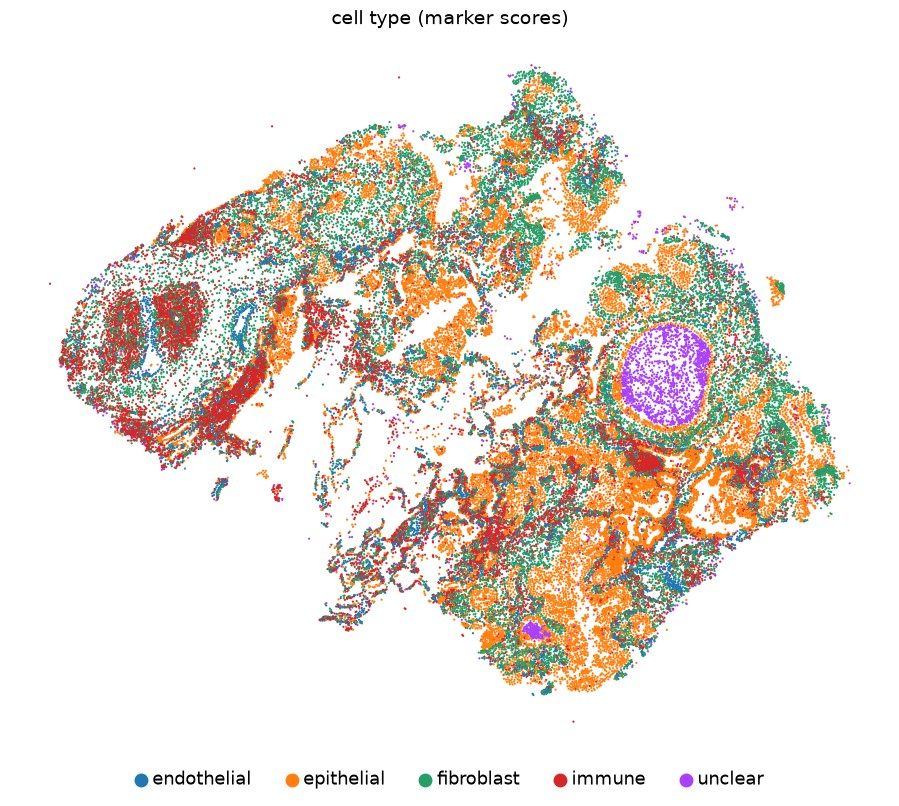

In [5]:
legend_below(cnv.pl.spatial_cnv(adata, color="cell_type", size=10, title="cell type (marker scores)", show=False))

## Gene positions

The genomic positions of the genes come from the GENCODE v44 annotation, downloaded once with {mod}`pooch`. The
Xenium panel lists Ensembl gene ids, which we match to the GTF.

In [6]:
gtf = pooch.retrieve(
    "https://ftp.ebi.ac.uk/pub/databases/gencode/Gencode_human/release_44/gencode.v44.annotation.gtf.gz",
    known_hash="sha256:01f817afed65feee863361b4baf30a95e722ee5c5d508ff77b04106ef7ba20d3",
    fname="gencode.v44.annotation.gtf.gz",
    path=pooch.os_cache("infercnvpy"),
)
cnv.io.genomic_position_from_gtf(gtf, adata, gtf_gene_id="gene_id", adata_gene_id="gene_ids")
print(f"{adata.var['chromosome'].notna().sum()} of {adata.n_vars} panel genes have a GENCODE position")
genes_per_chromosome = adata.var["chromosome"].value_counts()
genes_per_chromosome[genes_per_chromosome.index.str.fullmatch(r"chr[0-9]+")].agg(["min", "max"])

5001 of 5001 panel genes have a GENCODE position


min     58
max    536
Name: count, dtype: int64

## Which arms can this panel see?

Before we infer CNVs, {func}`infercnvpy.tl.detectability` estimates how many cells a test needs to detect a change of an
arm, when all of the cells are of one type and carry the same change. A chromosome arm is the part of a chromosome on
one side of its centromere, the short arm p or the long arm q. The function looks at the gain of one copy (1.5x, three
copies instead of two) and the loss of one copy (0.5x) of a whole arm. A test detects a change when it finds it with a
chance of 80%, at a rate of false calls of 1 in 1,000 per arm. The function doesn't find CNVs in your cells. A short
answer (few cells) means that a missing call is evidence against a clonal, one-copy change of the whole arm, but only
for a method that attains that power, and it doesn't mean that a call is real.

The function uses the raw counts, the depth and the expression of each cell type, and it measures the noise on the
reference cells. We give the cell types as `groupby`, so that each type gets its own row. The reference types get rows
too, which show what a change in those cells would need.

tl.detectability: 1 s
adata.uns['detectability']: ['table', 'params'] | adata.obs: 'detectability_information'


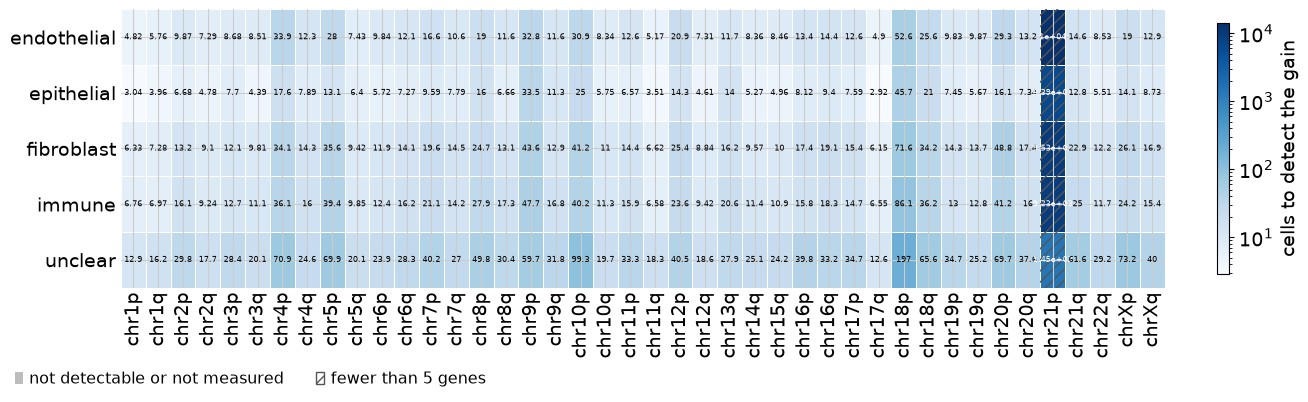

In [7]:
start = time.perf_counter()
cnv.tl.detectability(
    adata, layer="counts", groupby="cell_type", reference_key="cell_type", reference_cat=reference_types
)
print(f"tl.detectability: {time.perf_counter() - start:.0f} s")
print("adata.uns['detectability']:", list(adata.uns["detectability"]), "| adata.obs: 'detectability_information'")
cnv.pl.detectability(adata)

The heatmap shows the cells needed for a gain, per cell type (rows) and arm (columns), on a log scale. Each number is
the number of cells of that type, all carrying the change, that the test needs, and lighter tiles need fewer cells. Pass
`metric="cells_loss"` for losses. The unclear cells need the most, because they have the fewest counts. 21p is hatched
and dark, because it has fewer than 5 panel genes, and few genes carry little information. The p arms of chromosomes 13,
14, 15 and 22 hold no genes and have no column. chrY is left out by default, and chrX is included, which has one copy in
cells of a male donor.

`obs["detectability_information"]` is the Fisher information of each cell about the log copy ratio, summed over arms. It
grows with the cell's counts, and twice the information halves the cells needed. The map shows where on the section the
calls will be weaker. Most cells are below about 500, and a minority have more than 1,000.

0.1     80.0
0.5    230.0
0.9    590.0


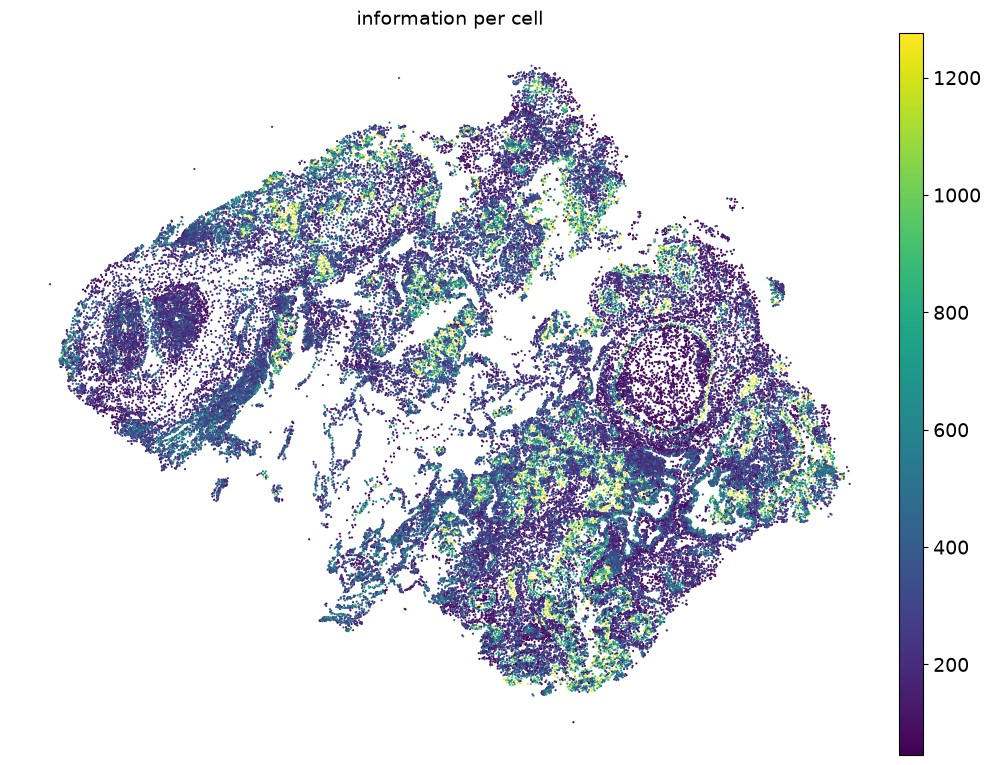

In [8]:
print(adata.obs["detectability_information"].quantile([0.1, 0.5, 0.9]).round(0).to_string())
cnv.pl.spatial_cnv(
    adata, color="detectability_information", size=10, cmap="viridis", vmax="p99", title="information per cell"
)

In [9]:
table = adata.uns["detectability"]["table"]
arms = table[table["group"] == "epithelial"].assign(arm=lambda t: t["arm"].astype(str)).set_index("arm")
blind = arms.index[(arms["n_genes"] < 5) | ~np.isfinite(arms["cells_gain"])]
print(f"arms with fewer than 5 genes or no information: {', '.join(blind)}")
print(f"null_var_source: {', '.join(table['null_var_source'].unique())}")
columns = ["n_genes", "null_var", "cells_gain", "cells_gain_ideal", "cells_loss", "cells_loss_ideal"]
summary = arms.loc[["chr3p", "chr3q"], columns].astype(float)
summary.loc["median over arms"] = arms[columns].median()
summary.round(1)

arms with fewer than 5 genes or no information: chr21p
null_var_source: measured


,n_genes,null_var,cells_gain,cells_gain_ideal,cells_loss,cells_loss_ideal
arm,,,,,,
chr3p,132.0,1.1,7.7,6.9,5.9,5.3
chr3q,144.0,1.1,4.4,3.8,3.3,2.9
median over arms,112.5,1.1,7.6,6.8,5.9,5.2


In [10]:
# the arms that need the most cells for a gain in the epithelial cells, and the other cell types against them
print(arms["cells_gain"].nlargest(5).round(0).to_string())
cells_gain = table.pivot_table(index="arm", columns="group", values="cells_gain", observed=True)
ratio = cells_gain.drop(index=blind).drop(columns="epithelial").div(cells_gain["epithelial"], axis=0)
print("cells for a gain relative to the epithelial cells, median over arms:")
print(ratio.median().round(1).to_string())

arm
chr21p    6395.0
chr18p      46.0
chr9p       34.0
chr10p      25.0
chr18q      21.0
cells for a gain relative to the epithelial cells, median over arms:
group
endothelial    1.5
fibroblast     1.9
immune         2.0
unclear        4.2


For the epithelial cells, the median arm needs about 8 cells to detect a gain and about 6 cells to detect a loss (table
above). A few arms need more, e.g. 34 cells for 9p and 46 for 18p (printed above, where 21p comes first because it has too few
genes). Over the other arms, fibroblasts and immune cells need about twice as many cells as epithelial cells (median ratios
1.9 and 2.0). Endothelial cells need 1.5 times as many, and cells of unclear type 4.2 times as many.

`null_var` says how much more an arm's signal varies in normal reference cells than counting noise alone predicts, e.g.
when a cell program moves the genes of an arm together. The achievable columns (`cells_gain`, `cells_loss`) include it,
and the ideal columns (`_ideal`) count only the noise of counting. Here `null_var` is about 1.1 for the median arm, so
the two columns are close. Plan with the achievable column. In a calibration on panel cuts of a breast cancer section
measured with 10x Atera, an oracle test that is given the true normal expression of every cell type needed about as many
cells as the achievable column predicts.

The achievable column is still a lower bound for real methods. {func}`infercnvpy.tl.infercnv` estimates the normal
expression from the data, and in the same calibration it needed about 2 to 6 times as many cells on a 5K panel, and on
panels of 1,000 genes or fewer it missed about a third of the arm events (see the calibration table of
{func}`infercnvpy.tl.detectability`). The numbers also assume that expression follows the DNA copies one to one, that
the tumor is near diploid, and that all tested cells carry the change. For a near-tetraploid tumor, pass `gain=1.25` and
`loss=0.75`, and if only a share f of the tested cells carry the change, multiply the cells needed by 1/f². The function
covers whole arms only, so focal events such as an amplification of SOX2 or MYC or a deletion of CDKN2A are not covered.

The reference has no normal epithelium, so the epithelial row borrows its null variance from the immune and stromal
cells. It describes the counting noise of epithelial cells, and not how well tumor and normal epithelium separate.

In [11]:
# What a smoothed neighborhood of 11 cells (a cell and its 10 neighbors, see below) can show on each arm
neighborhood = cnv.tl.detectability(
    adata,
    layer="counts",
    groupby="cell_type",
    reference_key="cell_type",
    reference_cat=reference_types,
    at_n_cells=11,
    inplace=False,
)
epithelial_11 = neighborhood[neighborhood["group"] == "epithelial"].assign(arm=lambda t: t["arm"].astype(str))
epithelial_11 = epithelial_11.set_index("arm")[["gain_ratio", "loss_ratio"]]
epithelial_11.loc["median over arms"] = epithelial_11.median()
epithelial_11.loc[["chr3p", "chr3q", "median over arms"]].round(2)

,gain_ratio,loss_ratio
arm,,
chr3p,1.41,0.63
chr3q,1.31,0.72
median over arms,1.41,0.63


With `at_n_cells=11`, the table gives the smallest gain and the mildest loss that 11 epithelial cells show in the
achievable columns, the size of a smoothed neighborhood below. For the median arm, 11 cells show a gain to about 1.4x
and a loss to about 0.63x, so the 11 cells of a full neighborhood are just enough for one copy (1.5x or 0.5x) in a test
that knows the normal expression. `tl.infercnv` needs 2 to 6 times as many cells as the about 8 cells of the median arm,
about 15 to 45. Many rows of the graph keep fewer than 10 neighbors after the mask below, and neighborhoods at the tumor
border mix in normal cells, so a single neighborhood will often miss a one-copy change. Changes become clear when many
neighborhoods share them, as 3p and 3q do below, and arms that need more cells, such as 9p and 18p, are not reliable at
this scale.

## Planning a panel

The same function helps to choose a panel and a depth before an experiment.

1. Take raw counts with gene positions from a similar tissue, e.g. a droplet atlas or an earlier section.
2. Pass the genes of each candidate panel as `genes`, and the expected median counts per cell as `depth`. Use the
   counts per cell that the vendor gives for the panel and tissue.
3. Check that the arms you care about need fewer cells than you expect per clone or per spatial neighborhood, with
   room for the factor that `tl.infercnv` needs on top (see above).

Here we use this section as the expression data and compare its full panel with a random subset of 400 of its genes,
at 100 and 300 counts per cell. The random subset is only a stand-in for a smaller panel, since a real targeted panel
picks its genes by cell type and not at random.

/localscratch/tim.treis/ipykernel_1620673/912067128.py:4: UserWarning: `depth` goes up to 13.6 times the observed median of 22 counts per cell. Beyond 2 times the extrapolation is unchecked, so those rows are rough; expression data at least as deep is better.
  name: cnv.tl.detectability(


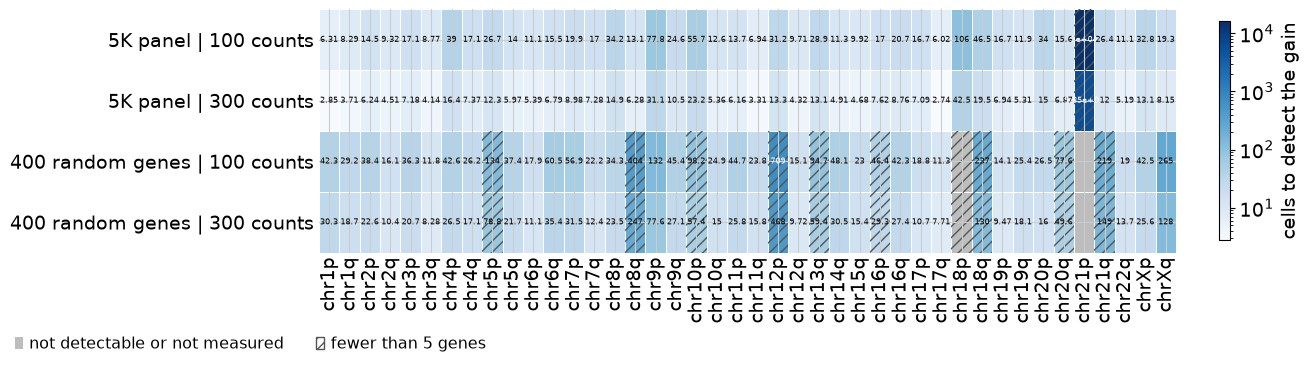

median_cells_gain null_var_source
                 depth                                   
5K panel         100.0               16.8        measured
                 300.0                7.1    extrapolated
400 random genes 100.0               42.3    extrapolated
                 300.0               25.6    extrapolated

In [12]:
rng = np.random.default_rng(0)
panels = {"5K panel": list(adata.var_names), "400 random genes": list(rng.choice(adata.var_names, 400, replace=False))}
plans = {
    name: cnv.tl.detectability(
        adata,
        genes=genes,
        layer="counts",
        groupby="cell_type",
        reference_key="cell_type",
        reference_cat=reference_types,
        depth=[100, 300],
        inplace=False,
    )
    for name, genes in panels.items()
}
epithelial_plans = {name: plan[plan["group"] == "epithelial"] for name, plan in plans.items()}
cnv.pl.detectability(epithelial_plans)
pd.concat(
    {
        name: plan.groupby("depth").agg(
            median_cells_gain=("cells_gain", "median"), null_var_source=("null_var_source", "first")
        )
        for name, plan in epithelial_plans.items()
    }
).round(1)

With the 5K panel, the median arm of the epithelial cells needs about 17 cells at 100 counts per cell and about 7 cells
at 300 counts. With the 400 random genes, it needs about 42 and 26 cells, many arms have fewer than 5 genes (hatched),
and 18p and 21p have no information at all (gray). At the same counts per cell, the smaller panel puts more counts on
each gene, but the counts of one gene vary between cells more than counting noise does, so more counts on fewer genes
help less than the same counts spread over more genes.

Rows above the counts that the genes have in this section are extrapolated (`null_var_source` is "extrapolated"). The 5K
panel at 300 counts is close to the observed depth (272 counts per cell). The 400 random genes hold roughly 20 counts
per cell here (about 400 of the 5,001 genes), so their rows at 100 and 300 counts are about 4.5 and 14 times the
observed depth. The extrapolation was checked up to about 2 times the observed depth, so those rows are rough, and
expression data at least as deep as the target is better. To turn cells needed into a tissue area, divide by the density
of the cell type in a comparable section.

## Infer CNVs and smooth them over the tissue

{func}`infercnvpy.tl.infercnv` runs as for single-cell data. The panel has 58 to 536 genes per autosome (printed above),
so we use running windows of 51 genes, every 5 genes, instead of the larger default windows. We turn off the noise
filter (`dynamic_threshold=None`), because it sets small values to 0 and {func}`infercnvpy.tl.smooth_cnv` would then
average those zeros. Then we build a spatial graph of the 10 nearest neighbors of each cell with squidpy and average
each cell's CNV profile with its neighbors. By default, the cell itself counts as one more neighbor.

In the graph, an edge links a cell to one of its nearest neighbors. With `reference_key` and `reference_cat`,
{func}`infercnvpy.tl.smooth_cnv` keeps only the edges within the reference cells and within the other cells. An immune
or stromal cell next to a tumor cell doesn't share the tumor's copy number changes, so smoothing over the edges between
them dilutes the tumor cells at the border and moves tumor signal into the reference cells there. The mask doesn't
remove tumor signal that such a cell carries in its own counts, e.g. from spillover (see
{func}`infercnvpy.tl.smooth_cnv`). The printout below counts, for each cell, the neighbors left after the mask. Cells
left with none keep their unsmoothed profile.

In [13]:
start = time.perf_counter()
cnv.tl.infercnv(
    adata,
    reference_key="cell_type",
    reference_cat=reference_types,
    window_size=51,
    step=5,
    dynamic_threshold=None,
)
print(f"tl.infercnv: {time.perf_counter() - start:.0f} s")
sq.gr.spatial_neighbors_knn(adata, n_neighs=10)
# smooth over the edges within the reference cells and within the other cells
cnv.tl.smooth_cnv(adata, reference_key="cell_type", reference_cat=reference_types)
# for the printout: neighbors per cell (row of the graph), before the mask and within the cell's own group after it
ref = adata.obs["cell_type"].isin(reference_types).to_numpy()
A = (adata.obsp["spatial_connectivities"] > 0).astype(int)
neighbors = pd.DataFrame(
    {"before the mask": np.asarray(A.sum(axis=1)).ravel(), "after": np.where(ref, A @ ref, A @ ~ref)}
)
print(
    f"graph symmetric: {(A != A.T).nnz == 0} | cells without neighbors after the mask: {(neighbors['after'] == 0).sum()}"
)
print(neighbors.describe(percentiles=[0.1, 0.25, 0.5]).loc[["min", "10%", "25%", "50%", "max"]].T.to_string())
adata.obsm["X_cnv"].shape, adata.obsm["X_cnv_smoothed"].shape

tl.infercnv: 0 s
INFO     Creating graph using `None` transform and `1` libraries.                                                  


graph symmetric: False | cells without neighbors after the mask: 679
                  min   10%   25%   50%   max
before the mask  10.0  10.0  10.0  10.0  10.0
after             0.0   5.0   8.0   9.0  10.0


((56265, 744), (56265, 744))

Each row of the squidpy graph lists the 10 nearest neighbors of a cell, and the graph is not symmetric (printed above),
so a cell can list another cell as a neighbor without being listed by it, and a cell can be the neighbor of more than 10
other cells. `tl.smooth_cnv` averages over the row, so a full neighborhood is a cell and its 10 neighbors. After the
mask, the median row keeps 9 neighbors, and at least a quarter of the rows keep 8 or fewer. The 679 cells whose row
keeps none stay unsmoothed.

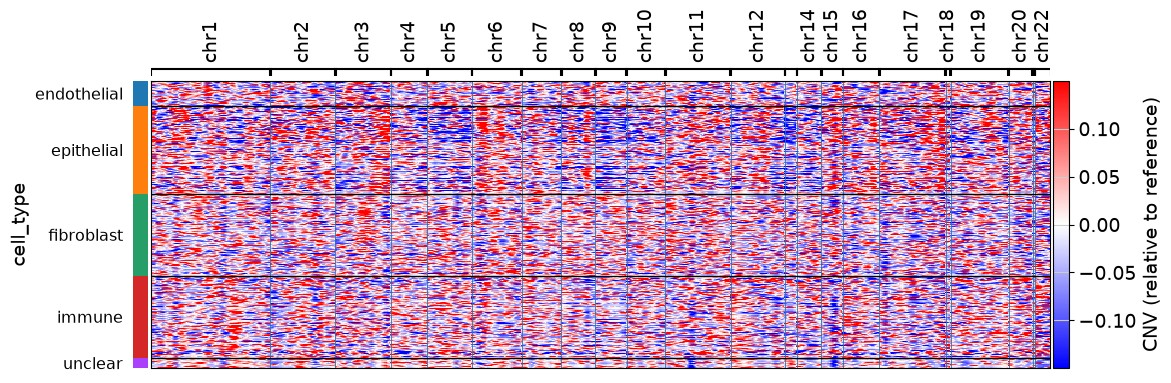

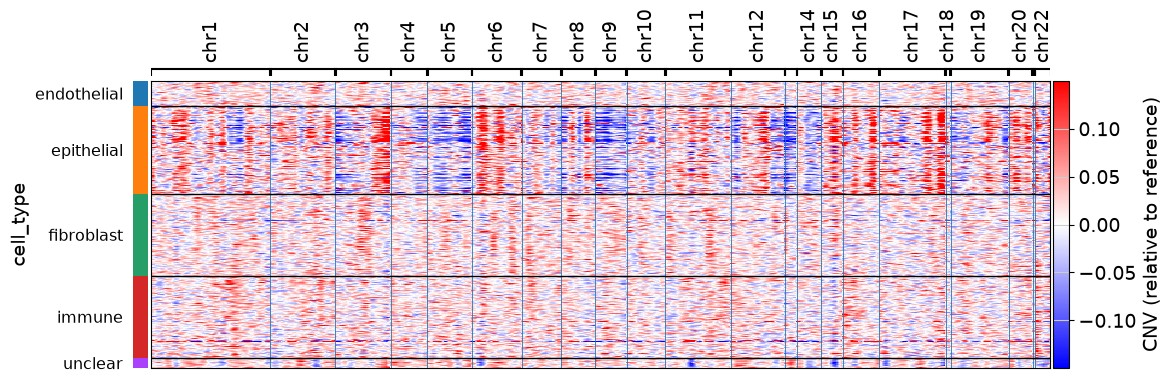

In [14]:
heatmap = {"groupby": "cell_type", "figsize": (12, 4), "vmin": -0.15, "vmax": 0.15}
cnv.pl.chromosome_heatmap(adata, **heatmap)
cnv.pl.chromosome_heatmap(adata, use_rep="cnv_smoothed", **heatmap)

Smoothing removes much of the noise of single cells, and the epithelial cells show a loss of 3p and a gain of 3q. On the
tissue, we plot the mean CNV of each arm of chromosome 3 (the windows whose midpoint lies in the arm, using the window
positions that `tl.infercnv` stores; the centromere is at about 91 Mb in GRCh38). The loss of 3p marks epithelial
regions of the section. The 3q map is red across most of the section, including regions of fibroblasts, which are
reference cells without a 3q gain. Expression differences between cell types alone therefore give a 3q signal. In the
smoothed heatmap it is about half the size of the epithelial one and lies on proximal instead of distal 3q, and the
color scale of the map hides the difference. The 3q map alone is not evidence of a gain. The detectability table says
that the panel holds enough counts on both arms, and it doesn't say whether the signal is copy number.

Part of the 3q signal of the epithelial cells may be lineage expression and not copy number. Squamous markers such as
SOX2 and TP63 sit on 3q, and the reference has no normal epithelium, so `tl.infercnv` compares squamous cells with
immune and stromal cells.

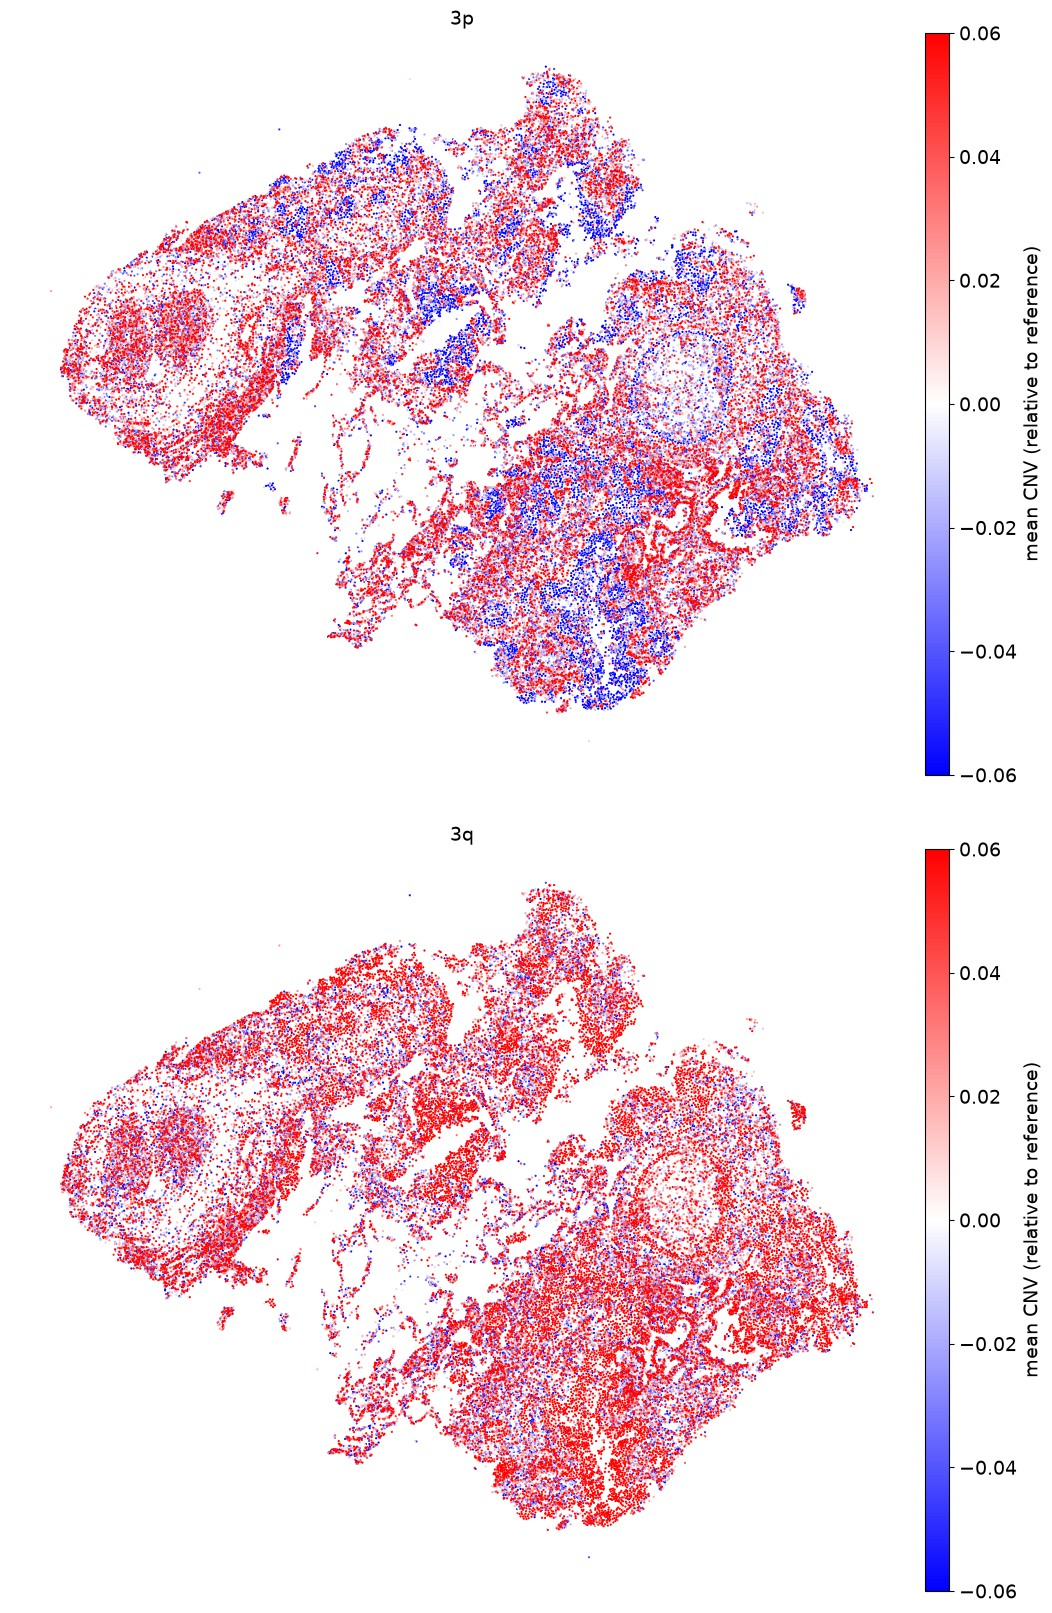

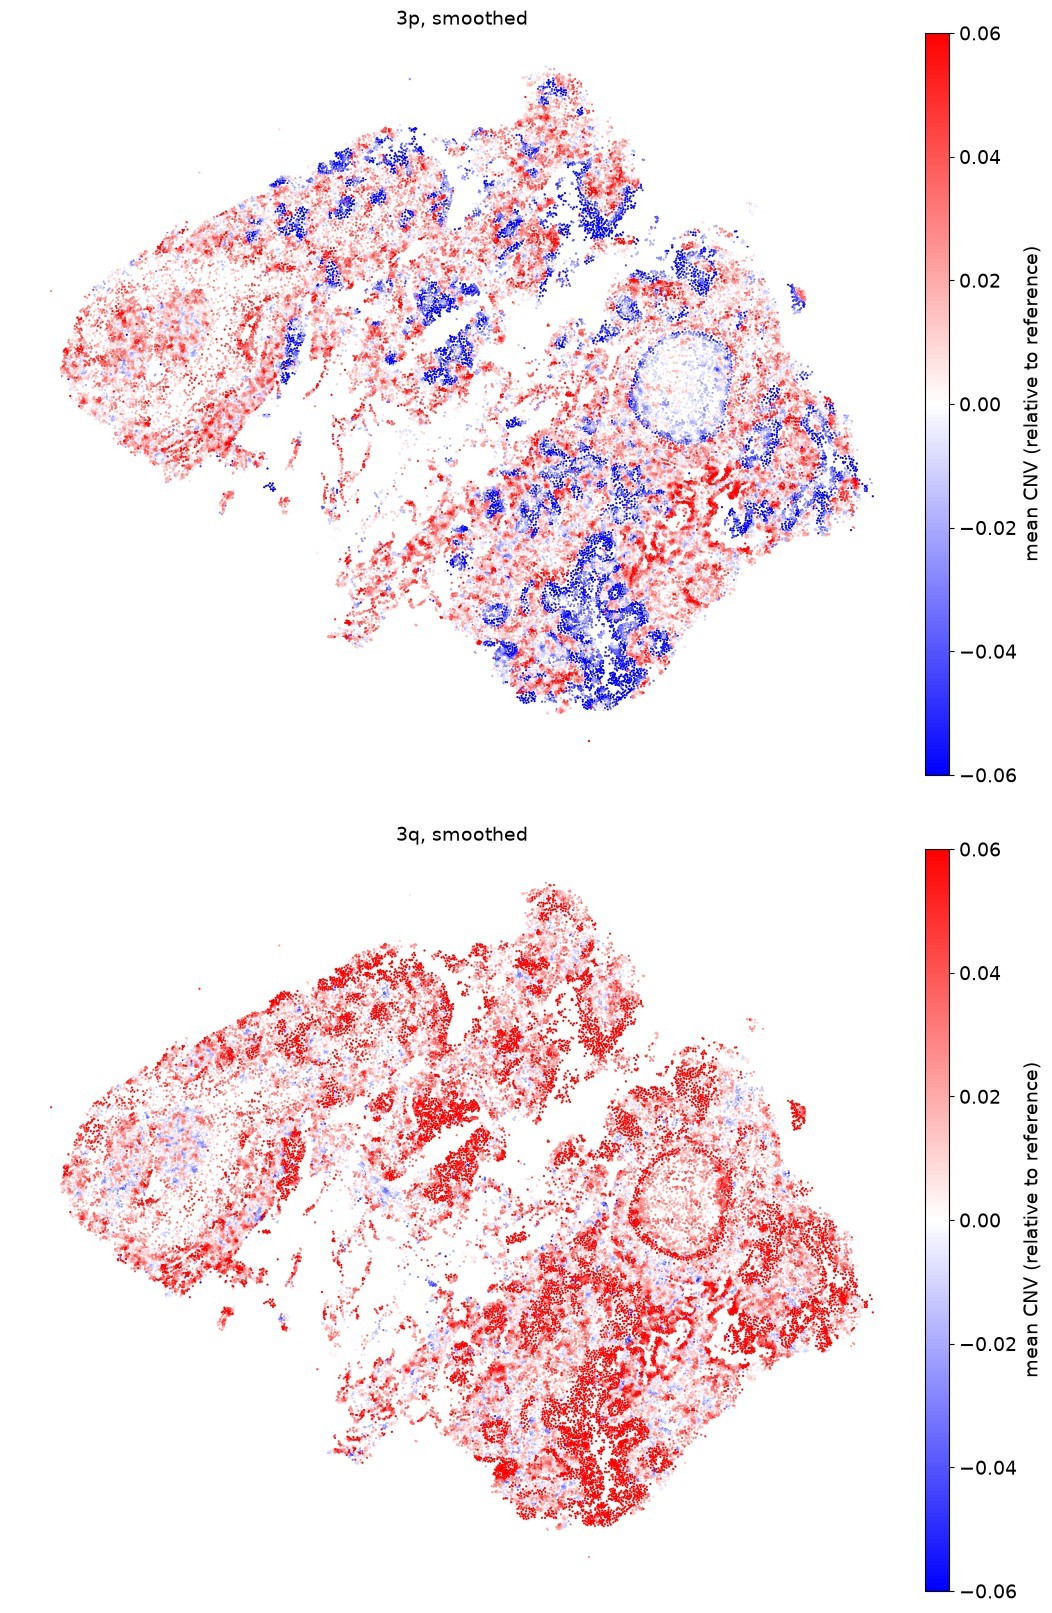

In [15]:
centromere = 90_900_000  # GRCh38 centromere midpoint of chr3, the split that tl.detectability uses
arms = [f"chr3:0-{centromere}", f"chr3:{centromere}-198_295_559"]
cnv.pl.spatial_cnv(adata, region=arms, size=10, ncols=1, hspace=0.1, vmin=-0.06, vmax=0.06, title=["3p", "3q"])
cnv.pl.spatial_cnv(
    adata,
    region=arms,
    use_rep="cnv_smoothed",
    size=10,
    ncols=1,
    hspace=0.1,
    vmin=-0.06,
    vmax=0.06,
    title=["3p, smoothed", "3q, smoothed"],
)

## Tumor calls

We score each cell by the mean absolute value of its smoothed CNV profile, and we call it tumor when the score is above
the 95th percentile of the scores of the reference cells. The score is per cell, and the threshold is one number from
the reference cells. By construction, 5% of the reference cells are called tumor, and normal cells of types outside the
reference can exceed the threshold as well.

Reference cells next to the tumor can carry tumor signal in their own counts, e.g. from spillover or from a segmentation
that merged them with a tumor cell, and such cells would raise the threshold. The second cell below checks for them. It
compares the reference cells within `max_distance` (60 µm, a few cell diameters) of the nearest epithelial cell with the
reference cells farther away, against the 95th percentile of the far cells. On the smoothed scores, the reference cells
at the border score higher even without tumor signal, because they keep fewer neighbors after the mask and their
smoothed profiles are noisier. The check therefore has two more rows. The unsmoothed scores include the cells right at
the border and don't depend on the neighbors. The cells that keep all 10 neighbors per row compare near and far cells at
the same number of neighbors, but they leave out the cells right at the border. If the near cells score higher in one of
these two rows, take the threshold from the far reference cells instead.

The reference has no normal epithelium here, so all epithelial cells stand in for the tumor when we measure the
distance. On your own data, measure the distance to the cells that hold the tumor, in µm (convert pixel coordinates
first).

In [16]:
reference = adata.obs["cell_type"].isin(reference_types).to_numpy()
cell_score = np.abs(adata.obsm["X_cnv_smoothed"]).mean(axis=1)
threshold = np.quantile(cell_score[reference], 0.95)
adata.obs["cnv_call"] = pd.Categorical(np.where(cell_score > threshold, "tumor", "normal"))
calls = pd.crosstab(adata.obs["cell_type"], adata.obs["cnv_call"])
calls["share tumor"] = (calls["tumor"] / calls.sum(axis=1)).round(3)
print(f"threshold: {threshold:.4f}")
print(
    f"tumor calls that are not epithelial: {calls['tumor'].sum() - calls.loc['epithelial', 'tumor']} of "
    f"{calls['tumor'].sum()} ({1 - calls.loc['epithelial', 'tumor'] / calls['tumor'].sum():.1%})"
)
calls

threshold: 0.0384
tumor calls that are not epithelial: 2280 of 15914 (14.3%)


cnv_call,normal,tumor,share tumor
cell_type,,,
endothelial,4794,199,0.040
epithelial,3474,13634,0.797
fibroblast,15409,570,0.036
immune,14974,1083,0.067
unclear,1700,428,0.201


In [17]:
max_distance = 60  # µm; the Xenium centroids are in µm, convert other coordinates first
# distance of each cell to the nearest epithelial cell, the cell type that holds the tumor here
epithelial_xy = adata.obsm["spatial"][(adata.obs["cell_type"] == "epithelial").to_numpy()]
distance = KDTree(epithelial_xy).query(adata.obsm["spatial"])[0]
far = reference & (distance > max_distance)
near = reference & ~far
full = (neighbors["after"] == 10).to_numpy()  # reference cells that keep all 10 neighbors per row after the mask
raw_cell_score = np.asarray(abs(adata.obsm["X_cnv"]).mean(axis=1)).ravel()
rows = {}
for name, score, cells in [
    ("smoothed, all reference cells", cell_score, np.ones_like(reference)),
    ("smoothed, all 10 neighbors kept", cell_score, full),
    ("unsmoothed, all reference cells", raw_cell_score, np.ones_like(reference)),
]:
    far_threshold = np.quantile(score[far & cells], 0.95)  # the 95th percentile of the far reference cells
    rows[name] = {
        "far cells": (far & cells).sum(),
        "near cells": (near & cells).sum(),
        "far above": (score[far & cells] > far_threshold).mean(),
        "near above": (score[near & cells] > far_threshold).mean(),
    }
print(f"reference cells more than {max_distance} µm from epithelium: {far.sum()} of {reference.sum()}")
pd.DataFrame(rows).T.astype({"far cells": int, "near cells": int}).round(3)

reference cells more than 60 µm from epithelium: 3966 of 37029


,far cells,near cells,far above,near above
"smoothed, all reference cells",3966,33063,0.05,0.119
"smoothed, all 10 neighbors kept",3635,15856,0.05,0.044
"unsmoothed, all reference cells",3966,33063,0.05,0.047


Most epithelial cells are called tumor (`share tumor` in the first table above). Of the tumor calls, 14.3% are not
epithelial (printed above). They are the 5% of reference cells above the threshold and 20.1% of the unclear cells, which
are not in the reference.

The check finds no excess in the near reference cells. On the smoothed profiles, 11.9% of the near cells score above the
95th percentile of the far ones. On the unsmoothed scores, the share is 4.7% near against 5% far, and among the cells
that keep all 10 neighbors per row it is 4.4% near against 5% far. So the excess on the smoothed profiles comes from the
near cells that keep fewer neighbors, and the threshold from all reference cells fits this section. The check has
limits. The near group holds most of the reference cells, so tumor signal in a thin band of cells next to the tumor
would raise its share only a little, and a percentile from a few thousand far cells is itself noisy. The far cells can
also differ from the near ones in their mix of cell types. On a section where the near cells score higher, take
`np.quantile(cell_score[far], 0.95)` as the threshold instead.

The main changes of the tumor calls are the loss of 3p and the gain of 3q, losses on chromosomes 5, 9, 13 and 14, losses
of distal 4q, 8p and 12p, and gains on 6, proximal 12q, 15, 16, 20, distal 8q and distal 17q.

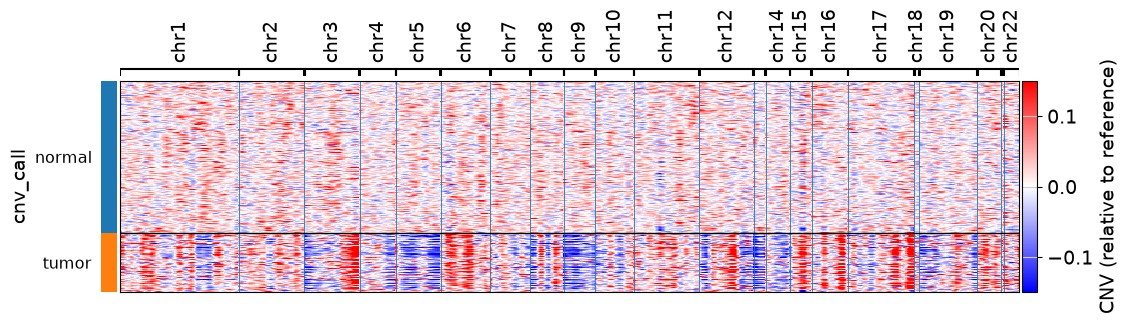

In [18]:
cnv.pl.chromosome_heatmap(adata, groupby="cnv_call", use_rep="cnv_smoothed", figsize=(12, 3), vmin=-0.15, vmax=0.15)

## Spatially coherent regions

{func}`infercnvpy.tl.spatial_regions` makes labels spatially coherent. A cell takes the label of its neighborhood when
enough neighbors disagree with it (for two labels and the default `beta=2`, more than 75% of them).

In [19]:
cnv.tl.spatial_regions(adata, key="cnv_call")
print(f"{(adata.obs['cnv_call'] != adata.obs['cnv_call_spatial']).sum()} of {adata.n_obs} cells changed their label")
pd.crosstab(adata.obs["cnv_call"], adata.obs["cnv_call_spatial"])

2223 of 56265 cells changed their label


cnv_call_spatial,normal,tumor
cnv_call,,
normal,40088,263
tumor,1960,13954


The calls from the smoothed profiles are already mostly coherent. 2,223 of the 56,265 cells changed their label (printed
above), most of them tumor calls that became normal. The prior matters more for noisy labels. Below, we call single
cells from the unsmoothed CNV profiles with the same rule, and we regularize the calls with `beta=4` (a cell changes its
label when more than 62.5% of its neighbors disagree).

In [20]:
raw_score = np.asarray(abs(adata.obsm["X_cnv"]).mean(axis=1)).ravel()
raw_threshold = np.quantile(raw_score[reference], 0.95)
adata.obs["cnv_call_raw"] = pd.Categorical(np.where(raw_score > raw_threshold, "tumor", "normal"))
cnv.tl.spatial_regions(adata, key="cnv_call_raw", beta=4)
epithelial = np.where(adata.obs["cell_type"] == "epithelial", "epithelial", "other")
keys = ["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"]
counts = pd.DataFrame({key: (adata.obs[key] == "tumor").groupby(epithelial).sum() for key in keys}).T
counts.assign(all=counts.sum(axis=1)).rename_axis("tumor calls")

,epithelial,other,all
tumor calls,,,
cnv_call_raw,6917,1933,8850
cnv_call_raw_spatial,4539,179,4718
cnv_call_spatial,12343,1874,14217


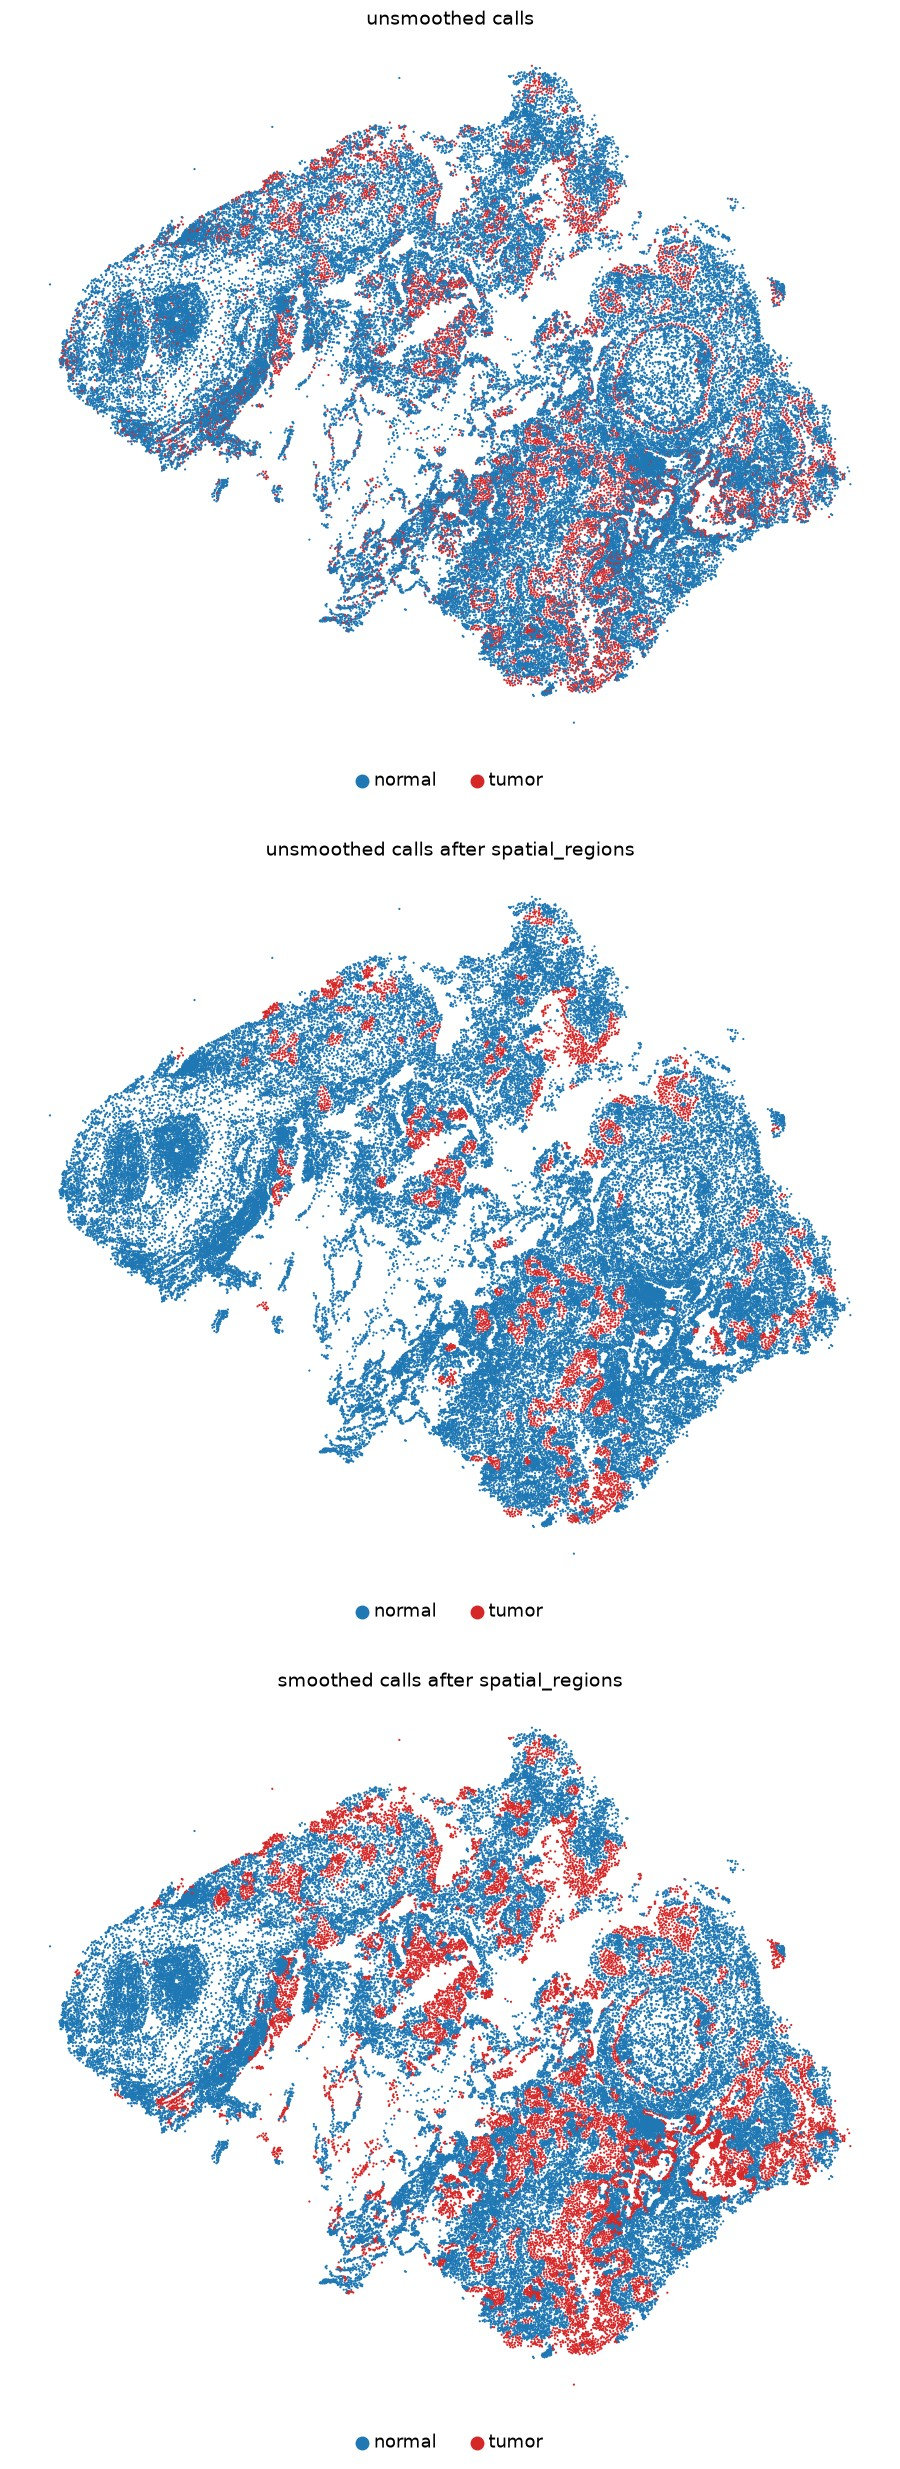

In [21]:
# tumor red and normal blue, as in the copy_number maps below
for key in ["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"]:
    adata.uns[f"{key}_colors"] = [
        {"normal": "#1f77b4", "tumor": "#d62728"}[c] for c in pd.Categorical(adata.obs[key]).categories
    ]
legend_below(
    cnv.pl.spatial_cnv(
        adata,
        color=["cnv_call_raw", "cnv_call_raw_spatial", "cnv_call_spatial"],
        size=10,
        ncols=1,
        hspace=0.15,
        title=["unsmoothed calls", "unsmoothed calls after spatial_regions", "smoothed calls after spatial_regions"],
        show=False,
    )
)

The calls from the unsmoothed profiles are scattered over the section (top). `tl.spatial_regions` removes about half of
them (8,850 to 4,718 in the `all` column above), including about 90% of the calls of non-epithelial cells (1,933 to 179,
middle). It doesn't recover tumor cells that the unsmoothed profiles miss, so the regularized calls from the smoothed
profiles (bottom) include more than twice as many epithelial cells (12,343 against 4,539). The two maps after `tl.spatial_regions`
(middle and bottom) use different values of `beta` (4 for the unsmoothed calls, 2 for the smoothed ones).

## Clones with tl.copy_number

{func}`infercnvpy.tl.copy_number` calls copy number from the raw counts with a count model. It returns aneuploid and
diploid labels, clones and segments (see {doc}`the API overview <../api>`). A clone is a group of cells that share the
same copy number profile. We give it the same reference cells and the full spatial graph from above, with
`connectivity_key`. The neighbors' calls then form part of each cell's prior, the probability of each clone before the
cell's own counts are seen, with a weight that `tl.copy_number` estimates from the data, up to `max_neighbor_weight`. A
cell with strong evidence of its own keeps its call, and a cell with few counts follows its neighborhood. In reference
mode, `tl.copy_number` always drops the edges between reference cells and the other cells, so we pass the full graph
here (`tl.smooth_cnv` drops them only when asked). The graph must be built on the same cells as `adata`, in the same
order, and a high neighbor weight can still spread calls into normal cells of the tumor's own type at the border.

Xenium cells have fewer detected genes than droplet cells, so we lower `min_genes` below its default, to 100. Cells
below it are labeled "not.defined". The next cell prints the distribution of detected genes per cell.

In [22]:
detected = pd.Series(np.asarray((adata.layers["counts"] > 0).sum(axis=1)).ravel())
print(detected.describe(percentiles=[0.1, 0.25, 0.5]).round(0).to_string())
print(f"cells with fewer than 100 detected genes: {(detected < 100).mean():.1%}")

count    56265.0
mean       284.0
std        228.0
min         31.0
10%         78.0
25%        131.0
50%        222.0
max       2210.0
cells with fewer than 100 detected genes: 16.0%


In [23]:
start = time.perf_counter()
cnv.tl.copy_number(
    adata,
    layer="counts",
    reference_key="cell_type",
    reference_cat=reference_types,
    min_genes=100,
    connectivity_key="spatial_connectivities",
)
print(f"tl.copy_number: {time.perf_counter() - start:.0f} s")
# the numbers of the small-panel check, after the filters of min_genes and min_detection
used = adata.uns["copy_number"]["genes"].index
called = (adata.obs["copy_number"] != "not.defined").to_numpy()
median_counts = np.median(np.asarray(adata[called, used].layers["counts"].sum(axis=1)).ravel())
print(f"genes passing the filters: {len(used)} (check: at least 1,000)")
print(f"median counts per cell in them: {median_counts:.0f} (check: at least 150)")
print(
    f"weight of the neighbors in each cell's prior: {adata.uns['copy_number']['spatial']['neighbor_weight']:.2f} "
    f"(cap: max_neighbor_weight={adata.uns['copy_number']['params']['max_neighbor_weight']})"
)
print("adata.uns['copy_number']:", list(adata.uns["copy_number"]))
print("adata.obs:", [k for k in adata.obs if k.startswith("copy_number")])
print(adata.obs["copy_number"].value_counts())
adata.uns["copy_number"]["clones"]

copy_number:   0%|          | 0/5 [00:00<?, ?restart/s]

tl.copy_number: 19 s
genes passing the filters: 2111 (check: at least 1,000)
median counts per cell in them: 275 (check: at least 150)
weight of the neighbors in each cell's prior: 0.01 (cap: max_neighbor_weight=0.8)
adata.uns['copy_number']: ['chr_pos', 'bins', 'window_start', 'window_end', 'clones', 'clone_profiles', 'segments', 'genes', 'seed', 'temperature', 'params', 'spatial', 'restarts']
adata.obs: ['copy_number', 'copy_number_score', 'copy_number_llr', 'copy_number_clone', 'copy_number_spillover', 'copy_number_stability']
copy_number
diploid         39128
not.defined      9022
aneuploid        8115
undetermined        0
Name: count, dtype: int64


,n_cells,aneuploid,amplitude,burden
N0,39128,False,0.008805,0.000000
T1,6324,True,0.176417,0.601611
T2,1791,True,0.161679,0.528186


The distribution of detected genes per cell has its 10th percentile at about 80 genes and its median at about 220, so
the threshold of 100 removes about 16% of the cells (printed above).

The panel passes the check of `tl.copy_number` for small panels, which needs at least 1,000 genes after its filters and
a median of 150 counts per cell in them. Here about 2,100 genes pass the filters, with a median of about 275 counts per
cell, so it calls the cells instead of labelling them "undetermined". The neighbors get a weight of about 0.01 in each
cell's prior, far below the cap of 0.8, so almost every cell keeps the call of its own counts. With numba's compiled
code cached, `tl.detectability` and `tl.infercnv` each took a few seconds on these cells, and `tl.copy_number` took
longer for its fits (see the timings printed above and the restarts below). The first call in a fresh environment also
compiles the code, which takes longer.

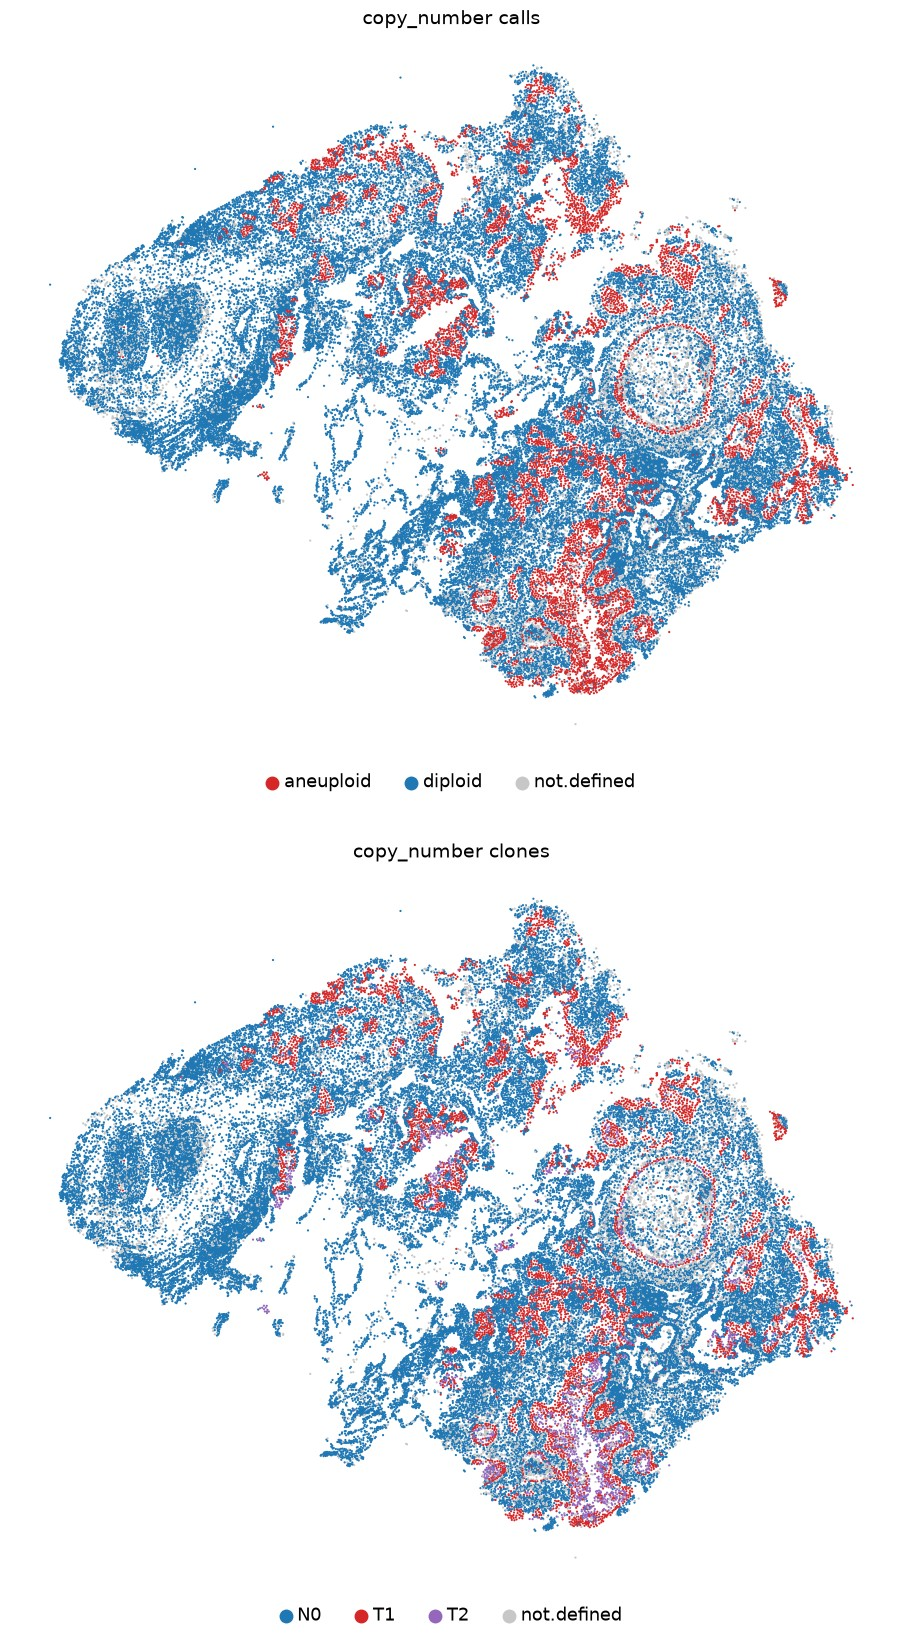

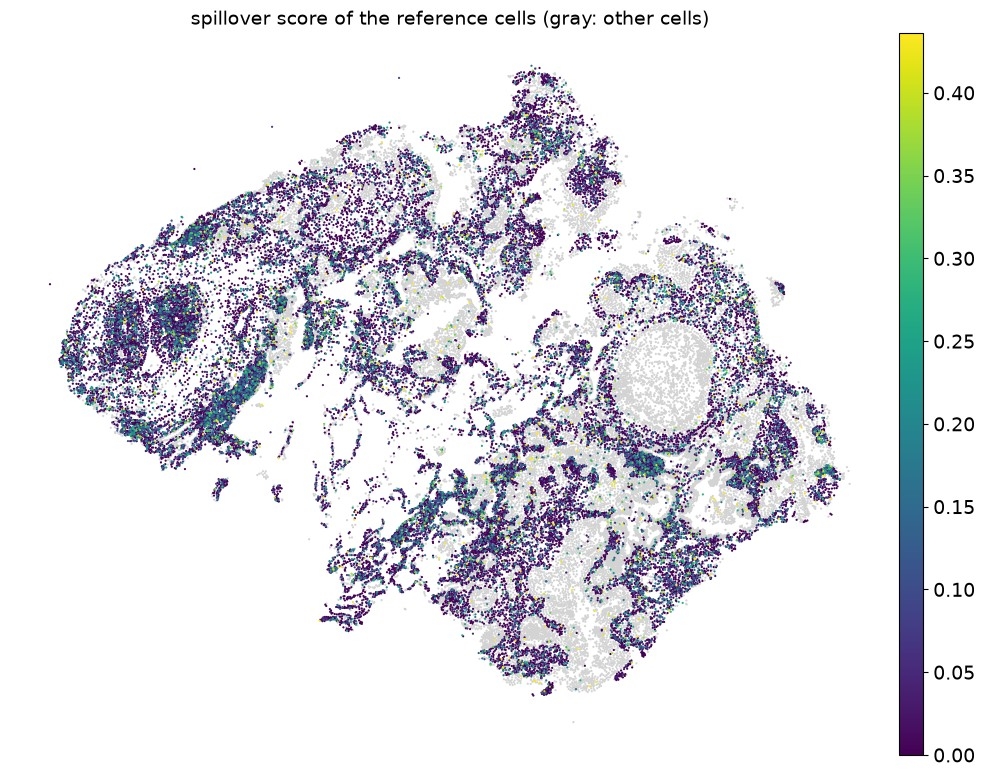

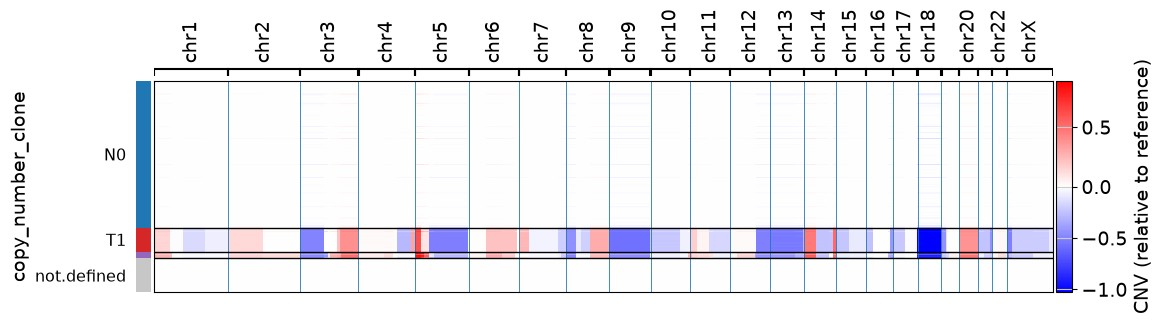

In [24]:
# one palette for the labels and the clones: aneuploid and T1 red, diploid and N0 blue, not.defined gray
palette = {"aneuploid": "#d62728", "T1": "#d62728", "diploid": "#1f77b4", "N0": "#1f77b4", "not.defined": "#c7c7c7"}
for key in ["copy_number", "copy_number_clone"]:
    adata.obs[key] = adata.obs[key].cat.remove_unused_categories()
    adata.uns[f"{key}_colors"] = [palette.get(c, "#9467bd") for c in adata.obs[key].cat.categories]
# spillover only in the reference cells, where a high value points to a merge with a tumor cell
in_reference = adata.obs["cell_type"].isin(reference_types)
adata.obs["spillover_reference"] = adata.obs["copy_number_spillover"].where(in_reference)
legend_below(
    cnv.pl.spatial_cnv(
        adata,
        color=["copy_number", "copy_number_clone"],
        size=10,
        ncols=1,
        hspace=0.15,
        title=["copy_number calls", "copy_number clones"],
        show=False,
    )
)
cnv.pl.spatial_cnv(
    adata,
    color="spillover_reference",
    size=10,
    cmap="viridis",
    vmax="p99",
    title="spillover score of the reference cells (gray: other cells)",
)
cnv.pl.chromosome_heatmap(adata, groupby="copy_number_clone", use_rep="copy_number", figsize=(12, 3))

`tl.copy_number` finds two aneuploid clones, T1 with about 6,300 cells and T2 with about 1,800, and labels about 39,000
cells diploid (clone N0). Diploid means that the cell fits the diploid clone better than any aneuploid clone. It can
still carry changes that no fitted clone holds, such as a small subclone, and it doesn't mean that the cell is normal.
The 9,000 cells with fewer than 100 detected genes are "not.defined", which we treat as unknown. In the clones table,
`burden` is the share of genes in long changed segments (60% for T1 and 53% for T2) and `amplitude` is the size of the
smooth profile. `copy_number_score` is each cell's probability of being aneuploid, and `copy_number_llr` is the evidence
of its own counts, without neighbors or priors.

In the clone heatmap, the main changes of T1 are a loss of 3p and a gain of distal 3q, a gain on 5p and a loss of 5q, a
gain of 6q, a loss of 8p and a gain of distal 8q, losses of 9, distal 12q, 13q and 18 (18 the deepest), a gain of
proximal 14q, and a gain of 20. Weaker losses appear on 10, 11q, mid 14q, 15, parts of 16, 17p, 21, X and distal 4q, and
weaker gains on distal 7p, distal 1p and 2p. The values are natural log copy ratios relative to the clone's average
level, because counts are compared after normalizing each cell's total, and they are not absolute copy numbers. One copy
lost in a diploid genome is ln 0.5 = -0.69, and one extra copy is ln 1.5 = +0.41, so they are not on the scale of the
`tl.infercnv` heatmaps above. 18 at about -1 or below (0.35x or less) next to 3p at about -0.5 fits a tumor that is not
near diploid better than one-copy losses in a diploid genome, and a whole-genome doubling would not show at all. Whether
the loss on X is real depends on the donor's sex, which we don't know here. T2, the thin purple row below T1, shares
most of these changes, with a stronger gain on 5p and on distal 3q, a weaker loss of 5q and 21, and no clear loss on
distal 4q, 10, 15 or 17.

We have no DNA measurement of the section to check the profile. The reference has no normal epithelium here either, so a
smooth difference between squamous and stromal expression can enter T1's profile, and the distal 3q gain covers SOX2 and
TP63. 9p and 18p need the most cells of all arms apart from 21p (see the detectability heatmap), and the clones of the
model are not proven subclones. Whether T2 splits off from T1 depends on the k-means seed (see the restarts below), so
read the split as a hint and not as a finding. The threshold calls of `tl.infercnv` and T1 disagree on 5p, 6p, 12p,
proximal 12q, 15, 16, 17 and 18. The deepest loss of T1, on 18, doesn't show in the threshold calls. `tl.infercnv`
smooths over arm borders and centers each cell, which shifts arms without a change when many arms change (see the
calibration notes of `tl.detectability`). For a reported profile, use `adata.uns["copy_number"]["segments"]`, with the
95% interval and `p_neutral` of each segment.

The spillover score is the share of a cell's counts that the pooled expression of the aneuploid cells explains best.
Read it only in the normal cell types, where high values point to segmentation merges with tumor cells, and also to
other causes, such as macrophages that take up tumor material or transcripts that diffuse between cells. The right panel
of the maps colors only the reference cells and leaves the other cells gray, since tumor cells score high by
construction. The table below compares the labels with the threshold calls from above (after `tl.spatial_regions`), per
cell type.

In [25]:
cell_type = adata.obs["cell_type"]
pd.DataFrame(
    {
        # share of cells per type: threshold tumor calls of tl.infercnv, and the labels of tl.copy_number
        "threshold tumor calls": (adata.obs["cnv_call_spatial"] == "tumor").groupby(cell_type, observed=True).mean(),
        "copy_number aneuploid": (adata.obs["copy_number"] == "aneuploid").groupby(cell_type, observed=True).mean(),
        "copy_number not.defined": (adata.obs["copy_number"] == "not.defined").groupby(cell_type, observed=True).mean(),
        "median spillover": adata.obs["copy_number_spillover"].groupby(cell_type, observed=True).median(),
        "spillover above 0.5": (adata.obs["copy_number_spillover"] > 0.5).groupby(cell_type, observed=True).mean(),
    }
).round(3)

,threshold tumor calls,copy_number aneuploid,copy_number not.defined,median spillover,spillover above 0.5
cell_type,,,,,
endothelial,0.035,0.000,0.058,0.000,0.004
epithelial,0.721,0.471,0.138,0.494,0.429
fibroblast,0.032,0.000,0.178,0.000,0.003
immune,0.060,0.000,0.144,0.009,0.006
unclear,0.111,0.027,0.568,0.000,0.004


`tl.copy_number` labels fewer epithelial cells aneuploid than the threshold calls, 47% of all epithelial cells against
72%. Neither set of labels is checked against pathology or DNA, and the tumor share may lie between them, but neither
share is validated. With reference cells, weak clones in shallow data can merge into the diploid clone (see the warnings
of `tl.copy_number`), so when a reference run calls few cells, run `tl.copy_number` without `reference_key` as well and
compare the two. Check also that `adata.uns["copy_number"]["clones"]` holds an aneuploid clone at all.

`tl.copy_number` labels almost none of the reference cells aneuploid (below 0.05%). In reference mode, the reference
cell types get a prior of 99% for the diploid clone and their neighbors count as diploid, so a reference cell is labeled
aneuploid only on strong evidence of its own, and their share is a weak check of false calls. The unclear cells are not
in the reference, but we don't know whether they are normal, and 57% of them are not.defined. About 3% of all unclear
cells are aneuploid, against 11% tumor calls by the regularized threshold calls, which is a check of false calls only if
these cells are normal. The threshold calls after `tl.spatial_regions` include 3% to 6% of the reference types, where
the threshold itself calls 5% by construction. The "not.defined" cells are 14% of the epithelial cells, 6% to 18% of the
reference types and more than half of the unclear cells. Below 1% of the cells of a reference type have a spillover
above 0.5, so few of them look like merges with tumor cells.

## Restarts of tl.copy_number

Before it fits the clones, `tl.copy_number` groups the cells into expression types with k-means, which starts from a
random seed. By default it fits 5 times, each with its own seed, and keeps the fit whose calls agree most with those of
the other fits. Below we compare single fits (`n_restarts=1`) at three values of `random_state` with the run above.

In [26]:
called_5 = adata.obs["copy_number"].isin(["aneuploid", "diploid"])
fits = {
    "n_restarts=5 (above)": {
        "aneuploid cells": (adata.obs["copy_number"] == "aneuploid").sum(),
        "aneuploid clones": adata.uns["copy_number"]["clones"]["aneuploid"].sum(),
        "same call as above": 1.0,
    }
}
for seed in [0, 1, 2]:
    obs, _, uns, _ = cnv.tl.copy_number(
        adata,
        layer="counts",
        reference_key="cell_type",
        reference_cat=reference_types,
        min_genes=100,
        connectivity_key="spatial_connectivities",
        n_restarts=1,
        random_state=seed,
        inplace=False,
        show_progress=False,
    )
    fits[f"n_restarts=1, random_state={seed}"] = {
        "aneuploid cells": (obs["copy_number"] == "aneuploid").sum(),
        "aneuploid clones": uns["clones"]["aneuploid"].sum(),
        # share of the called cells with the same aneuploid or diploid call as the run with 5 restarts
        "same call as above": (obs["copy_number"].astype(str) == adata.obs["copy_number"].astype(str))[called_5].mean(),
    }
pd.DataFrame(fits).T.astype({"aneuploid cells": int, "aneuploid clones": int}).round(3)

,aneuploid cells,aneuploid clones,same call as above
n_restarts=5 (above),8115,2,1.000
"n_restarts=1, random_state=0",8224,1,0.991
"n_restarts=1, random_state=1",8061,1,0.993
"n_restarts=1, random_state=2",8053,2,0.994


Here the calls barely move between fits, and the split into clones does. Two of the three single fits find one aneuploid
clone, and one finds two. On harder data, single fits can differ more, also in their calls, and the restarts make the
result depend less on the seed. They don't make it more correct. As a check per cell, `copy_number_stability` holds the
share of the 5 fits whose call, made without the neighbors, matches the cell's label.

In [27]:
restarts = adata.uns["copy_number"]["restarts"]
print(f"fit kept: {restarts['chosen']} | aneuploid cells per fit: {restarts['n_aneuploid'].tolist()}")
below_1 = (adata.obs.loc[called_5, "copy_number_stability"] < 1).mean()
print(f"called cells with a stability below 1: {below_1:.1%}")

fit kept: 1 | aneuploid cells per fit: [8215, 8114, 8043, 8066, 8046]
called cells with a stability below 1: 1.5%


1.5% of the called cells have a stability below 1, so their label depends on the seed or differs from the fits because
of the spatial prior. Treat those calls as uncertain, like the "not.defined" cells. The score covers only the aneuploid
or diploid call and not the clone, so a cell with a stability of 1 can still move between T1 and T2 from one fit to the
next.

## Notes

- With 10 neighbors and the default weight of the cell itself, a cell's own profile is 1/11 of its smoothed profile, so
  calls from smoothed profiles are calls of neighborhoods. With the reference mask of `tl.smooth_cnv`, this holds for
  cells that keep all 10 neighbors. Cells at the border between reference and other cells keep fewer, so their own
  profile weighs more, and cells whose neighbors are all on the other side keep their own profile. Smoothing mixes the
  profiles of tumor cells and normal cells outside the reference (e.g. normal epithelium) at the tumor boundary, over
  about `n_hops` cells. Use the unsmoothed `X_cnv` for per-cell questions in mixed regions.
- The spatial graph defines the neighborhood. A kNN graph adapts to the cell density, and a radius graph
  ({func}`squidpy.gr.spatial_neighbors_radius`) keeps the physical scale fixed. `n_hops=2` in `tl.smooth_cnv` widens the
  neighborhood further.
- `tl.spatial_regions` changes labels only as long as a single change makes them more coherent, so the result stays
  close to the input labels and is not a new clustering. Larger `beta` gives smoother regions.
- For several sections in one AnnData, build the graph per section with `library_key` in
  {func}`squidpy.gr.spatial_neighbors_knn`, so that no cell gets neighbors from another section, and measure the
  distance to the epithelium per section for the check of the threshold. Sections of different depth are best run one by
  one through `tl.detectability` and the threshold calls, because a pooled reference quantile mixes depths.
  `tl.copy_number` fits one diploid baseline and one set of clones over all the cells that it gets.
- On small panels (fewer than 1,000 usable genes) or below a median of 150 counts per cell, `tl.copy_number` labels the
  cells "undetermined". Run `tl.detectability` to see which arms the panel can resolve, and then `tl.infercnv` with
  `tl.smooth_cnv`. The calls of `tl.copy_number(force_calls=True)` are not calibrated on such panels.

In [28]:
# versions and threads used to run this notebook; INFERCNVPY_COMMIT is set by the docs build
print("infercnvpy", cnv.__version__, os.environ.get("INFERCNVPY_COMMIT", ""))
packages = [
    "anndata",
    "scanpy",
    "squidpy",
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "numba",
    "pynndescent",
    "igraph",
]
for package in packages:
    print(package, importlib.metadata.version(package))
print("numba threads", numba.get_num_threads(), "| CPUs", os.cpu_count())

infercnvpy 0.7.0rc2.dev6+g9bc2ac8 9bc2ac8
anndata 0.13.4
scanpy 1.12.6
squidpy 1.8.4
numpy 2.5.5
pandas 3.1.1
scipy 1.18.1
scikit-learn 1.9.1
numba 0.68.1
pynndescent 0.6.0


igraph 1.0.0
numba threads 16 | CPUs 96
